In [ ]:
%%capture
!pip install datasets transformers

In [ ]:
from transformers import BertTokenizer

# Machine Learning for NLP

# Building blocks

In this part, we will discover how to build a first neural network for text classification, step by step.

🚧 **TODO** 🚧

Propose a chain of operations that should be applied to the input text, from the input to the output.
When it applies, write the dimension of the expected tensors.

**Answer**

- Tokenizer le texte
- Mapper les IDs aux embeddings
- Aggréger les embeddings en un seul vecteur de taille `d` par document
- Classifier multi-classes à partir de ce vecteur de document

## Tokenizer

During the last course and during the HW, you used a `WhiteSpaceTokenizer` to tokenize the text.

Here, we are going to use the tokenizer from the model `Bert`, that we will describe later in the course. It comes with the `transformers` library.

In [ ]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased", do_lower_case=True)

In [ ]:
sent = "I love footballing"
ids = tokenizer.encode(sent)
for i in ids:
    print(i, tokenizer.convert_ids_to_tokens(i))

101 [CLS]
1045 i
2293 love
2374 football
2075 ##ing
102 [SEP]


In [ ]:
len(tokenizer)

30522

**Dataset**

We will use the AGNews dataset. It is a dataset with 4 classes: World, Sports, Business, Sci/Tech. We download it from HuggingFace Hub [here](https://huggingface.co/datasets/fancyzhx/ag_news).

In [ ]:
from datasets import load_dataset
import unicodedata
import re

dataset = load_dataset("fancyzhx/ag_news")
dataset = dataset["train"]
dataset = dataset.shuffle(seed=42)
dataset = dataset.select(range(3000))
# dataset = dataset.select(range(500))
dataset = dataset.train_test_split(test_size=0.3)

print(dataset)


def preprocess_text(text: str) -> str:
    # TODO lower case
    text = text.lower()

    # TODO string normalization.
    text = unicodedata.normalize("NFD", text).encode("ascii", "ignore").decode()

    # TODO remove non alpha numeric characters.
    text = re.sub(r"[^a-z0-9]", " ", text)

    # TODO replace numbers by the <NUM> token.
    text = re.sub(r"\d+", "<NUM>", text)

    # TODO remove double whitespaces.
    text = re.sub(" +", " ", text.strip())
    return text


# Clean the dataset
dataset = dataset.map(lambda x: {"text": preprocess_text(x["text"])})

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 2100
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 900
    })
})


Map:   0%|          | 0/2100 [00:00<?, ? examples/s]

Map:   0%|          | 0/900 [00:00<?, ? examples/s]

In [ ]:
dataset['train'][:10]

{'text': ['courtesy counts but drivers outside the chase won <NUM> t be giving any lt b gt lt b gt it was evident when their <NUM> cars were herded away from their less fortunate brethren by scurrying officials immediately after the cutoff race at richmond international raceway two weeks ago',
  'china blast traps miners in toxic shafts a gas explosion that tore through a coal mine in central china trapped <NUM> workers in underground shafts filled with noxious smoke in the latest and apparently the deadliest of a',
  'billy joel gets a star in hollywood los angeles billy joel wrote the song say goodbye to hollywood on monday he joked he d never leave it looks like i m always going be here joel said after his sidewalk star was unveiled on the hollywood walk of fame',
  'russian hostel fire kills at least <NUM> moscow reuters a fire in a russian workers hostel killed at least <NUM> people and may have injured many more the emergencies ministry said on wednesday',
  'snowstorm in midwest

## Word vectors

The first step since we have access to text in a tokenized form is to use word embeddings.

### Embeddings


🚧 **TODO** 🚧

Experiment with the class `nn.Embedding` from PyTorch.

Construct an embedding layer with:
- `d_embed=50` dimensions
- `n_vocab=V` words in the vocabulary

Then try to get the embedding of the following sentence: `"I love machine learning."`.

In [ ]:
from torch import nn
import torch

#--- TODO ---
d_embed = 50
n_vocab = len(tokenizer) #
print('n_vocab: ', n_vocab)
print('d_embed: ', d_embed)

embedding_model = nn.Embedding(
    num_embeddings=n_vocab, embedding_dim=d_embed )
#------
print('Embedding model shape:', embedding_model.weight.shape) #

sentence = "I love machine learning"
tokens = tokenizer(sentence, return_tensors="pt")["input_ids"]
print('Token ids of "%s":'%sentence, tokens)
print([" ".join(tokenizer.convert_ids_to_tokens(token)) for token in tokens])
vectors = embedding_model(tokens)

print('Embedding of "%s":'%sentence)
print('shape:', vectors.shape)


n_vocab:  30522
d_embed:  50
Embedding model shape: torch.Size([30522, 50])
Token ids of "I love machine learning": tensor([[ 101, 1045, 2293, 3698, 4083,  102]])
['[CLS] i love machine learning [SEP]']
Embedding of "I love machine learning":
shape: torch.Size([1, 6, 50])


In [ ]:
sentence = "I love Paris"
tokens = tokenizer(sentence, return_tensors="pt")["input_ids"]
print('Token ids:', tokens)
vectors = embedding_model(tokens)
print('Embedding:')
print(vectors.shape)

Token ids: tensor([[ 101, 1045, 2293, 3000,  102]])
Embedding:
torch.Size([1, 5, 50])


### Aggregation function

Since we need to perform document classfications, we need to aggregate the embeddings into a single vector of size `d`.

### Classification

The last layer of the network should be a linear layer with `c` classes.

🚧 **TODO** 🚧

Write a class named "WordEmbedClassifier" that will take as input a list of ids and return the probability of each class.

In [ ]:
class WordEmbedClassifier(nn.Module):
    def __init__(self, vocab_size, d, n_classes=4):
        super().__init__()
        self.embedding_layer = nn.Embedding(num_embeddings=vocab_size, embedding_dim=d)

        self.class_projection = nn.Linear(d, n_classes)

    def forward(self, x):
        # x (B, L)
        x_embeds = self.embedding_layer(x) # (B, L, d)

        x_vector = x_embeds.mean(axis=1) # (B, d)

        class_logits = self.class_projection(x_vector) # (B, n_classes)

        # class_proba = torch.nn.functionnal.softmax(class_logits)
        return class_logits

In [ ]:
# Try the model on a simple input:
length = 10
model = WordEmbedClassifier(d=50, n_classes=4, vocab_size=len(tokenizer))

print('Information about "model":', model)
for name, p in model.named_parameters():
    print(name, p.shape)
for p in model.parameters():
    print(p.shape)

Information about "model": WordEmbedClassifier(
  (embedding_layer): Embedding(30522, 50)
  (class_projection): Linear(in_features=50, out_features=4, bias=True)
)
embedding_layer.weight torch.Size([30522, 50])
class_projection.weight torch.Size([4, 50])
class_projection.bias torch.Size([4])
torch.Size([30522, 50])
torch.Size([4, 50])
torch.Size([4])


In [ ]:
# x = tokenizer(["I live Paris", "I live Paris"], return_tensors="pt")["input_ids"]
x = tokenizer(["I live Paris", "I love Paris"], return_tensors="pt")["input_ids"]
print(x.shape)
output = model(x)
print(output.shape)
print(output)


torch.Size([2, 5])
torch.Size([2, 4])
tensor([[-0.3865, -0.2822,  0.3441, -0.2679],
        [-0.4414, -0.3409,  0.4141, -0.0674]], grad_fn=<AddmmBackward0>)


## Training

For training we need to iterate over the dataset.

### Data preparation

Here, we will assume that all texts have the same length, using truncation and discarding examples.

🚧 **Question** 🚧

Why do we need to have inputs of the same length?

**Answer**

Because we put them into tensors.

In [ ]:

def tokenize_truncate_and_discard(texts_list, labels_list, tokenizer, length=50):
    new_texts = []
    new_labels = []
    for text, label in zip(texts_list, labels_list):
        tokenized_text = tokenizer.encode(text)
        if len(tokenized_text) < length:
            continue
        new_texts.append(tokenized_text[:length])
        new_labels.append(label)

    return new_texts, new_labels


train_texts, train_labels = tokenize_truncate_and_discard(
    dataset["train"]["text"], dataset["train"]["label"], tokenizer,
    length = 50
)
test_texts, test_labels = tokenize_truncate_and_discard(
    dataset["test"]["text"], dataset["test"]["label"], tokenizer,
    length = 50
)

train_dataset = [(t, l) for t, l in zip(train_texts, train_labels)]
valid_dataset = [(t, l) for t, l in zip(test_texts, test_labels)]

print("Size before truncating:", len(dataset["train"]["text"]))
print("Size after truncating:", len(train_texts))

print("Size before truncating:", len(dataset["train"][0]['text']))
print("Size after truncating:", len(train_texts[0]))


Size before truncating: 2100
Size after truncating: 942
Size before truncating: 281
Size after truncating: 50


Now we need to make batches of examples. We will use the DataLoader class from PyTorch.

🚧 **TODO** 🚧

Load the data into batches. One batch should be a dictionary with the following keys:
- `"input_ids"`: tensor of size (batch_size, L)
- `"labels"`: tensor of size (batch_size,)

In [ ]:
from torch.utils.data import DataLoader


class DataCollator:
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer

    def __call__(self, batch):
        # `batch` is a list of tuples (text, label)
        texts, labels = zip(*batch)
        # Encode the texts
        return {"input_ids": torch.tensor(texts), "labels": torch.tensor(labels)}


data_collator = DataCollator(tokenizer)

batch_size = 32

train_dataloader = DataLoader(
    train_dataset, batch_size=batch_size, collate_fn=data_collator, shuffle=True
)
valid_dataloader = DataLoader(
    valid_dataset, batch_size=batch_size, collate_fn=data_collator, shuffle=True
)
n_valid = len(valid_dataset)
n_train = len(train_dataset)

🔴 **TEST**

In [ ]:
batch = next(iter(train_dataloader))
print(batch)
assert isinstance(batch, dict)
assert "input_ids" in batch
assert "labels" in batch
assert isinstance(batch["input_ids"], torch.Tensor)
assert isinstance(batch["labels"], torch.Tensor)
assert batch["input_ids"].shape[0] == batch_size
assert batch["labels"].shape[0] == batch_size

print(batch["input_ids"].shape)

{'input_ids': tensor([[  101, 13156,  3509,  ...,  3509,  2075,  2006],
        [  101,  2079, 14510,  ...,  2019,  3988,  2270],
        [  101,  1044, 25619,  ...,  1996,  9044,  2358],
        ...,
        [  101, 10651,  1026,  ...,  9878,  1996,  2728],
        [  101,  3066,  2489,  ..., 10650,  2104,  2019],
        [  101, 11956, 27092,  ...,  5725,  5963,  9043]]), 'labels': tensor([0, 2, 2, 1, 3, 0, 1, 0, 2, 3, 0, 0, 1, 0, 2, 0, 1, 2, 1, 3, 3, 0, 1, 3,
        1, 3, 0, 0, 1, 2, 0, 1])}
torch.Size([32, 50])


### Training loop

🚧 **TODO** 🚧

Now write the training loop. Validate the model on the validation set every epoch. Don't forget to plot the learning curves.

In [ ]:
import matplotlib.pyplot as plt
from torch import optim

# TODO
def validation_step(valid_dataloader, model, criterion):
    n_valid = len(valid_dataloader.dataset)
    model.eval()
    total_loss = 0.0
    correct = 0
    n_iter = 0
    with torch.no_grad():
        for batch in valid_dataloader:
            input_ids = batch["input_ids"]
            labels = batch["labels"]
            output = model(input_ids)
            loss = criterion(output, labels)
            total_loss += loss.item()
            correct += (output.argmax(axis=-1) == batch["labels"]).sum().item()
            n_iter += 1
    return total_loss / n_iter, correct / n_valid


def train_one_epoch(train_dataloader, model, optimizer, criterion):
    model.train()
    total_loss = 0.0
    correct = 0
    n_train = len(train_dataloader.dataset)
    n_iter = 0
    for batch in train_dataloader:
        optimizer.zero_grad()
        class_scores = model(batch["input_ids"]) # (B, 4)

        loss = criterion(class_scores, batch["labels"]) # scalaire (1,)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (class_scores.argmax(axis=-1) == batch["labels"]).sum().item()
        n_iter += 1

    return total_loss / n_iter, correct / n_train


def train(model, train_dataloader, valid_dataloader, lr=0.01, n_epochs=10):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    # Track training loss, training accuracy, validation loss and validation accuracy and plot in the end
    train_losses = []
    train_accuracies = []
    valid_losses = []
    valid_accuracies = []

    for epoch in range(n_epochs):
        train_loss, train_accuracy = train_one_epoch(
            train_dataloader, model, optimizer, criterion
        )
        valid_loss, valid_accuracy = validation_step(valid_dataloader, model, criterion)
        print(
            f"Epoch {epoch + 1}: train_loss: {train_loss:.4f}, train_accuracy: {train_accuracy:.4f}, valid_loss: {valid_loss:.4f}, valid_accuracy: {valid_accuracy:.4f}"
        )
        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        valid_losses.append(valid_loss)
        valid_accuracies.append(valid_accuracy)

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label="train loss")
    plt.plot(valid_losses, label="valid loss")
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(train_accuracies, label="train accuracy")
    plt.plot(valid_accuracies, label="valid accuracy")
    plt.legend()

# model = WordEmbedClassifier(d=10, n_classes=4, vocab_size=len(tokenizer))
model = WordEmbedClassifier(d=50, n_classes=4, vocab_size=len(tokenizer)) # emb dim = 50

# train(model, train_dataloader, valid_dataloader, n_epochs=10)

Epoch 1: train_loss: 1.3267, train_accuracy: 0.3747, valid_loss: 1.2450, valid_accuracy: 0.4600
Epoch 2: train_loss: 1.0017, train_accuracy: 0.7378, valid_loss: 0.9630, valid_accuracy: 0.6775
Epoch 3: train_loss: 0.5351, train_accuracy: 0.9076, valid_loss: 0.7350, valid_accuracy: 0.7400
Epoch 4: train_loss: 0.2341, train_accuracy: 0.9682, valid_loss: 0.6535, valid_accuracy: 0.7600
Epoch 5: train_loss: 0.1093, train_accuracy: 0.9894, valid_loss: 0.6378, valid_accuracy: 0.7850
Epoch 6: train_loss: 0.0572, train_accuracy: 0.9979, valid_loss: 0.6271, valid_accuracy: 0.7875
Epoch 7: train_loss: 0.0349, train_accuracy: 1.0000, valid_loss: 0.6312, valid_accuracy: 0.7850
Epoch 8: train_loss: 0.0234, train_accuracy: 1.0000, valid_loss: 0.6072, valid_accuracy: 0.7875
Epoch 9: train_loss: 0.0175, train_accuracy: 1.0000, valid_loss: 0.6077, valid_accuracy: 0.7850
Epoch 10: train_loss: 0.0132, train_accuracy: 1.0000, valid_loss: 0.6125, valid_accuracy: 0.7875


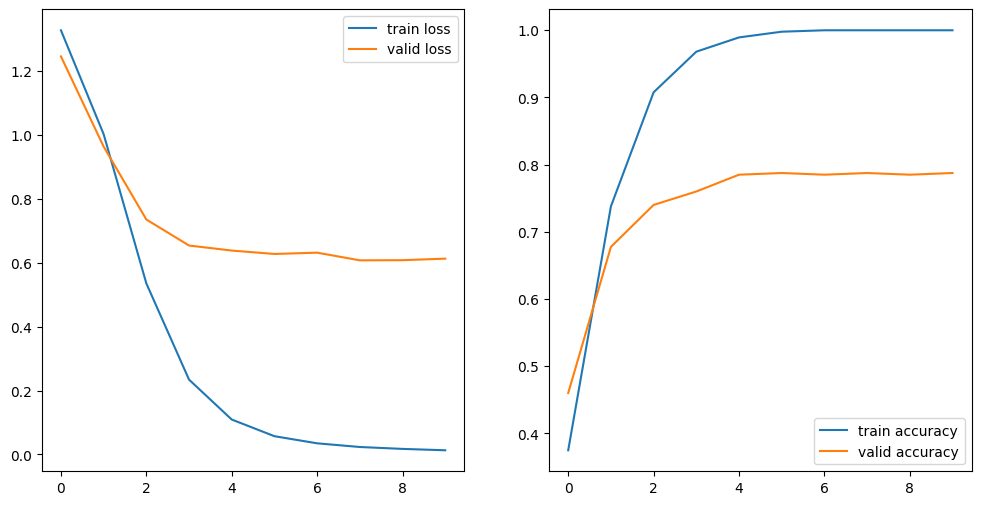

In [ ]:
train(model, train_dataloader, valid_dataloader, n_epochs=10)

🚧 **TODO** 🚧

What do you think about the learning curves ?

## Padding and masking

Up to know, we assumed that our texts have the same length. To achieve that, we truncated the texts. However, in practice we want to keep the full texts (up to a given limit, of course)

We will investigate masking and padding to handle texts of different lengths.

🚧 **Question** 🚧

- What will padding achieve?
- What should we be careful about when using padding model?

**Answer**

TODO


In [ ]:
# pad token
print('pad token id in tokenizer:', tokenizer.pad_token_id)

# data collector using padding
class DataCollator:
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer

    def __call__(self, batch):
        # Tokenize the texts
        texts = [example["text"] for example in batch]
        labels = [example["label"] for example in batch]
        tokenized_texts = [self.tokenizer.encode(text) for text in texts]
        # Pad the tokenized texts
        max_len = max(len(text) for text in tokenized_texts)
        padded_texts = [
            text + [self.tokenizer.pad_token_id] * (max_len - len(text))
            for text in tokenized_texts
        ]
        pad_mask = [
            [1] * len(text) + [0] * (max_len - len(text)) for text in tokenized_texts
        ]
        return {
            "input_ids": torch.tensor(padded_texts),
            "pad_mask": torch.tensor(pad_mask),
            "labels": torch.tensor(labels),
        }

batch_size = 32
n_train = len(dataset["train"])
n_valid = len(dataset["test"])
data_collator = DataCollator(tokenizer)
train_dataloader = DataLoader(
    dataset["train"], batch_size=batch_size, collate_fn=data_collator, shuffle=True
)
valid_dataloader = DataLoader(
    dataset["test"], batch_size=batch_size, collate_fn=data_collator, shuffle=True
)

pad token id in tokenizer: 0


In [ ]:
print(dataset["train"].shape)

(2100, 2)


In [ ]:
# run a few times to see the tokens in the batch, now using padding
batch = next(iter(train_dataloader))
print(batch["input_ids"][:2, :])
# print(batch["input_ids"][:2, -50:])
print(batch["input_ids"].shape)
print(batch["pad_mask"].shape)


tensor([[  101,  2146, 14655, 13695,  8670,  2050,  2000,  1026, 16371,  2213,
          1028,  1049,  5618,  8670,  2050,  3725,  1026, 16371,  2213,  1028,
          1055,  2364,  3199,  6872,  2387,  2049,  2034,  2431, 11372,  2061,
          2906,  2011,  1026, 16371,  2213,  1028,  2004,  5157, 18852,  2426,
          6209, 12088,  1998,  2449, 19284,  2005,  2146, 14655,  7599,  2013,
          9895, 10524,   102,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0],
        [  101,  9486,  8162,  3401, 10217,  2000,  4965, 11603,  9722,  2859,
          4684,  6499,  6199,  9486,  8162,  3401,  4297,  2029,  2038,  2464,
          2049,  3745,  1997,  1996, 27291,  3274,  3006, 22088, 11368,  2056,
          2006,  9317,  2008,  2009

🚧 **TODO** 🚧

Update the code of the `WordEmbedClassifier` to handle padding.


In [ ]:

class WordEmbedClassifier(nn.Module):
    def __init__(self, vocab_size, d, n_classes=4, pad_id=0):
        super().__init__()

        self.pad_id = pad_id

        self.embedding_layer = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=d,
            padding_idx=pad_id
        )
        self.class_projection = nn.Linear(d, n_classes)

    def forward(self, x, pad_mask):
        # pad_mask: (B, L)
        # x: (B, L)
        x_masked = x * pad_mask
        x_embeds = self.embedding_layer(x_masked)  # (B, L, d)

        # count real tokens
        lengths = pad_mask.sum(dim=1, keepdim=True)  # (B, 1)
        # avoid division by zero
        lengths = lengths.clamp(min=1)

        # masked mean
        x_vector = x_embeds.sum(dim=1) / lengths  # (B, d) / (B,1)

        class_logits = self.class_projection(x_vector)

        return class_logits

🔴 **TEST**

In [ ]:
model = WordEmbedClassifier(d=50, n_classes=4, vocab_size=10000)

seq_len = 10
x_without_pad = torch.randint(0, 10000, (1, seq_len))
pad_mask = torch.ones(1, seq_len, dtype=torch.long) # Specify dtype as long
out_without_pad = model(x_without_pad, pad_mask)

x_with_pad = torch.randint(0, 10000, (1, 2 * seq_len))
pad_mask = torch.ones(1, 2 * seq_len, dtype=torch.long) # Specify dtype as long
pad_mask[:, seq_len:] = 0
out_with_pad = model(x_with_pad, pad_mask)

assert out_without_pad.shape == out_with_pad.shape



In [ ]:
# TODO
def validation_step(valid_dataloader, model, criterion):
    n_valid = len(valid_dataloader.dataset)
    model.eval()
    total_loss = 0.0
    correct = 0
    n_iter = 0
    with torch.no_grad():
        for batch in valid_dataloader:
            input_ids = batch["input_ids"]
            labels = batch["labels"]
            pad_mask = batch["pad_mask"]
            output = model(input_ids, pad_mask)
            loss = criterion(output, labels)
            total_loss += loss.item()
            correct += (output.argmax(axis=-1) == batch["labels"]).sum().item()
            n_iter += 1
    return total_loss / n_iter, correct / n_valid


def train_one_epoch(train_dataloader, model, optimizer, criterion):
    model.train()
    total_loss = 0.0
    correct = 0
    n_train = len(train_dataloader.dataset)
    n_iter = 0
    for batch in train_dataloader:
        optimizer.zero_grad()
        class_scores = model(batch["input_ids"], batch["pad_mask"]) # (B, 4)

        loss = criterion(class_scores, batch["labels"]) # scalaire (1,)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (class_scores.argmax(axis=-1) == batch["labels"]).sum().item()
        n_iter += 1

    return total_loss / n_iter, correct / n_train


def train(model, train_dataloader, valid_dataloader, lr=0.01, n_epochs=5):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Track training loss, training accuracy, validation loss and validation accuracy and plot in the end
    train_losses = []
    train_accuracies = []
    valid_losses = []
    valid_accuracies = []

    for epoch in range(n_epochs):
        train_loss, train_accuracy = train_one_epoch(
            train_dataloader, model, optimizer, criterion
        )
        valid_loss, valid_accuracy = validation_step(valid_dataloader, model, criterion)
        print(
            f"Epoch {epoch + 1}: train_loss: {train_loss:.4f}, train_accuracy: {train_accuracy:.4f}, valid_loss: {valid_loss:.4f}, valid_accuracy: {valid_accuracy:.4f}"
        )
        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        valid_losses.append(valid_loss)
        valid_accuracies.append(valid_accuracy)

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label="train loss")
    plt.plot(valid_losses, label="valid loss")
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(train_accuracies, label="train accuracy")
    plt.plot(valid_accuracies, label="valid accuracy")
    plt.legend()

Epoch 1: train_loss: 1.2235, train_accuracy: 0.5019, valid_loss: 0.9671, valid_accuracy: 0.6744
Epoch 2: train_loss: 0.5638, train_accuracy: 0.8595, valid_loss: 0.5714, valid_accuracy: 0.7911
Epoch 3: train_loss: 0.2012, train_accuracy: 0.9519, valid_loss: 0.5396, valid_accuracy: 0.8144
Epoch 4: train_loss: 0.0803, train_accuracy: 0.9886, valid_loss: 0.5138, valid_accuracy: 0.8167
Epoch 5: train_loss: 0.0373, train_accuracy: 0.9962, valid_loss: 0.5170, valid_accuracy: 0.8278
Epoch 6: train_loss: 0.0198, train_accuracy: 0.9990, valid_loss: 0.5300, valid_accuracy: 0.8267
Epoch 7: train_loss: 0.0125, train_accuracy: 1.0000, valid_loss: 0.5458, valid_accuracy: 0.8256
Epoch 8: train_loss: 0.0088, train_accuracy: 1.0000, valid_loss: 0.5804, valid_accuracy: 0.8244
Epoch 9: train_loss: 0.0064, train_accuracy: 1.0000, valid_loss: 0.5663, valid_accuracy: 0.8244
Epoch 10: train_loss: 0.0050, train_accuracy: 1.0000, valid_loss: 0.5538, valid_accuracy: 0.8256


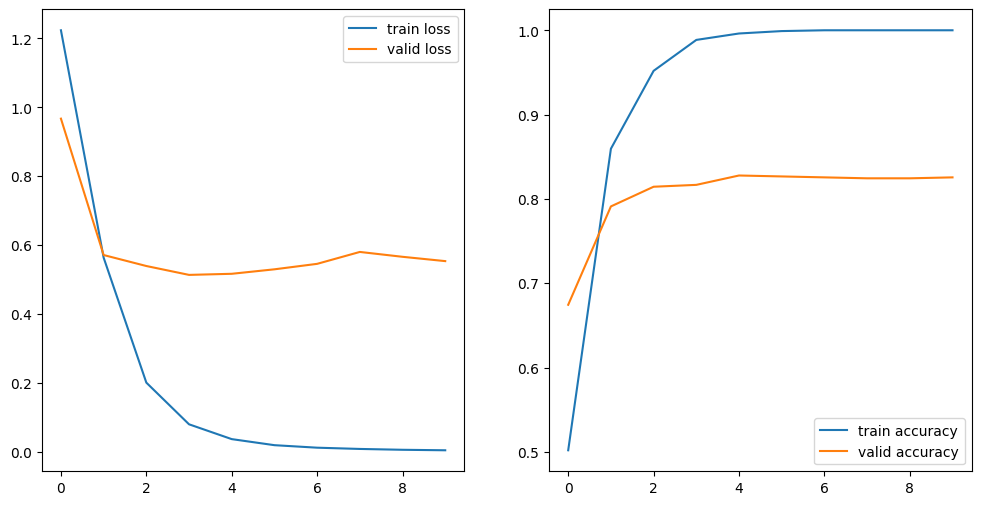

In [ ]:
model = WordEmbedClassifier(
    d=50,
    n_classes=4,
    vocab_size=len(tokenizer),
)
train(
    model,
    train_dataloader=train_dataloader,
    valid_dataloader=valid_dataloader,
    lr=0.01,
    n_epochs=10,
)

## Sequence processing module

Now we built a simple classifier using word embeddings.

But is our model really different from a simple bag-of-words model?

🚧 **Question** 🚧

How can we make our model more powerful?

**Answer**

TODO

🚧 **Question** 🚧

What kind of module can we use?

**Answer**

TODO

## Convolution1D

Look at the documentation of the Conv1d layer. Read it carefully and try to completely understand the following code. A convolution layer expects a tensor as input, with the following dimensions *(B, D, L)*:
- B: size of the batch, the number of examples (here the number of sequences).
- D: the dimension of the vectors for each time step
- L: the length of the input sequence (the number of tokens in the sequence).

🚧 **Question** 🚧

Is this shape directly compatible with our Embeddings layer defined above?

🚧 **TODO** 🚧

- Make sure the following code computing a convolution run and is consistent.
- Draw what happens to better understand the obtained dimensions.

In [ ]:
d_embed = 50
embedding_layer = nn.Embedding(num_embeddings=len(tokenizer), embedding_dim=d_embed)

sequence_embedding = embedding_layer(batch["input_ids"][:2])
print("Sequence embedding shape:", sequence_embedding.shape)

convolution_layer = nn.Conv1d(in_channels=d_embed, out_channels=d_embed, kernel_size=3)
convolution_output = convolution_layer(sequence_embedding.transpose(1, 2)) # convolution input should be (B, D, L)
print("Convolution output shape:", convolution_output.shape)
output = convolution_output.transpose(1, 2)

Sequence embedding shape: torch.Size([2, 91, 50])
Convolution output shape: torch.Size([2, 50, 89])


🚧 **TODO** 🚧

Write a class named "Conv1dClassifier" that implements a convolutional neural network for text classification.

In [ ]:
class ConvClassifier(nn.Module):
    def __init__(self, vocab_size, d, n_classes=4):
        super().__init__()
        self.embedding_layer = nn.Embedding(vocab_size, d)
        self.class_projection = nn.Linear(d, n_classes)
        self.conv1 = nn.Conv1d(d, d, kernel_size=3)
        self.conv2 = nn.Conv1d(d, d, kernel_size=3)

    def forward(self, input_ids, pad_mask):
        x_embed = self.embedding_layer(input_ids) # (B, L, d)
        x_embed = x_embed * pad_mask[:, :, None]
        x_embed = self.conv1(x_embed.transpose(1, 2))

        x_embed = torch.relu(x_embed)

        x_embed = self.conv2(x_embed).transpose(1, 2)

        # x_vector = x_embeds.mean(axis=1) # (B, d)
        pad_mask = pad_mask[:, 2:-2]
        n_non_pad = pad_mask.sum(axis=1, keepdim=True) # (B, 1), 1 because of keepdim=True
        # pad_mask (B, L), x_embed (B, L, d)
        x_embed = x_embed * pad_mask[:, :, None] # or pad_mask.unsqueeze(-1)
        x_vector  = x_embed.sum(axis=1) / n_non_pad

        class_scores = self.class_projection(x_vector) # (B, n_classes)
        return class_scores


Epoch 1: train_loss: 1.3850, train_accuracy: 0.2814, valid_loss: 1.3835, valid_accuracy: 0.2711
Epoch 2: train_loss: 1.3755, train_accuracy: 0.2929, valid_loss: 1.3805, valid_accuracy: 0.3089
Epoch 3: train_loss: 1.3633, train_accuracy: 0.3448, valid_loss: 1.3630, valid_accuracy: 0.3333
Epoch 4: train_loss: 1.3375, train_accuracy: 0.3810, valid_loss: 1.3342, valid_accuracy: 0.3867
Epoch 5: train_loss: 1.2873, train_accuracy: 0.4343, valid_loss: 1.2918, valid_accuracy: 0.4056
Epoch 6: train_loss: 1.2005, train_accuracy: 0.4829, valid_loss: 1.2312, valid_accuracy: 0.4422
Epoch 7: train_loss: 1.0947, train_accuracy: 0.5467, valid_loss: 1.1624, valid_accuracy: 0.4844
Epoch 8: train_loss: 0.9900, train_accuracy: 0.5829, valid_loss: 1.1211, valid_accuracy: 0.5067
Epoch 9: train_loss: 0.8922, train_accuracy: 0.6390, valid_loss: 1.0757, valid_accuracy: 0.5567
Epoch 10: train_loss: 0.8056, train_accuracy: 0.6829, valid_loss: 1.0463, valid_accuracy: 0.5722


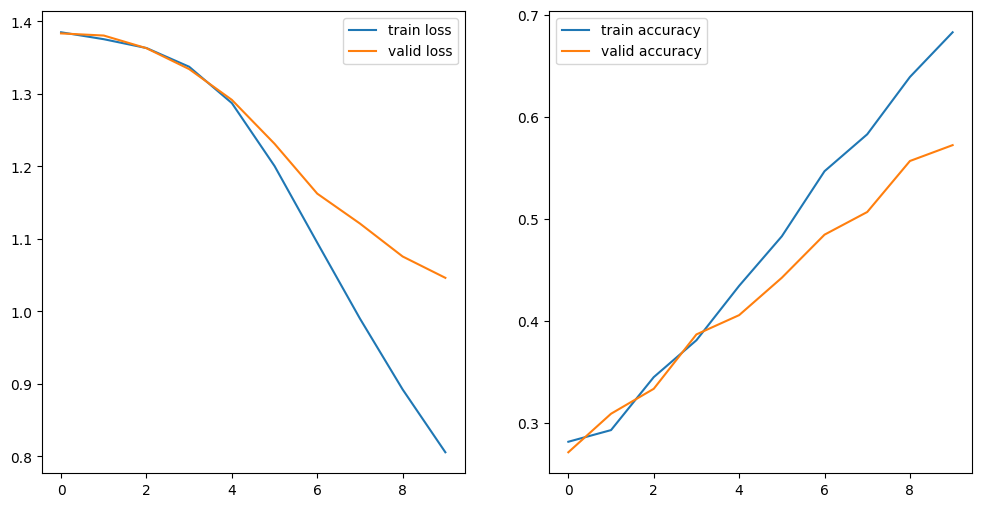

In [ ]:
model = ConvClassifier(
    d=10,
    n_classes=4,
    vocab_size=len(tokenizer),
)
train(
    model,
    train_dataloader=train_dataloader,
    valid_dataloader=valid_dataloader,
    lr=0.001,
    n_epochs=10,
)